# code_066 · Batching and structure-preserving transformations

**Book:** section 13.5. A self-contained structure-preserving input laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_13_GUIDE.md), [run evidence](../CHAPTER_13_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_066).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1366;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1366


<a id="batch"></a>
## Concatenation must preserve entity boundaries

Batch a three-node chain and a separate two-node edge into a disconnected union. Offset every second-graph node index by three; retain a graph-membership vector for per-entity pooling. Block-diagonal adjacency should produce the same neighbor aggregation as separate calls. A missing offset silently assigns the second graph's edges to first-graph nodes even when no obvious out-of-range index appears. This NumPy construction demonstrates the mechanism, not a PyTorch Geometric runtime.

Uniformly sampling two of four neighbors can approximate a mean with nonzero finite-sample variability. Enumerate all six pairs for values [0,0,0,100]: pair means differ, although their average equals the full mean 25. That expectation result concerns uniform sampling and a linear mean; it does not establish an unbiased nonlinear graph-network prediction. Mesh coarsening similarly requires new connectivity, boundary retention and field-transfer checks rather than arbitrary row deletion.


In [2]:
from itertools import combinations
A1=np.array([[0,1,0],[1,0,1],[0,1,0.]]);A2=np.array([[0,1],[1,0.]]);A=np.zeros((5,5));A[:3,:3]=A1;A[3:,3:]=A2;X=np.array([1,2,3,10,20.])[:,None];batch=np.array([0,0,0,1,1]);edges1=np.array([[0,1],[1,0],[1,2],[2,1]]);edges2=np.array([[0,1],[1,0]])+3;edges=np.vstack([edges1,edges2])
assert np.all(batch[edges[:,0]]==batch[edges[:,1]]) and np.all(edges2>=3)
np.testing.assert_allclose(A@X,np.vstack([A1@X[:3],A2@X[3:]]));assert not A[:3,3:].any() and not A[3:,:3].any()
pool=np.array([X[batch==j].mean() for j in range(2)]);np.testing.assert_allclose(pool,[2,15]);assert not np.allclose(pool,X.mean())
neighbor=np.array([0,0,0,100.]);pairmeans=np.array([neighbor[list(pair)].mean() for pair in combinations(range(4),2)]);np.testing.assert_allclose(pairmeans.mean(),neighbor.mean());assert pairmeans.min()!=pairmeans.max()
RESULTS['graph_batch']={'nodes':5,'entities':2,'pooled_means':pool.tolist(),'no_cross_entity_edges':True};RESULTS['neighbor_sampling']={'full_mean':float(neighbor.mean()),'all_uniform_pair_means':pairmeans.tolist(),'mean_over_pairs':float(pairmeans.mean())}


<a id="masks"></a>
## Padding and graph membership are part of the input

Two sequences have lengths four and two, including an actual zero. Their mask-aware mean ignores padded entries even if padded storage is changed to a huge value. Masking a loss is distinct from masking an encoder or an attention operation: both must respect the intended information boundary. This example audits only a masked mean, without claiming to implement causal attention or an entire sequence network.


In [3]:
values=np.array([[0,1,2,3],[4,6,0,0.]]);mask=np.array([[1,1,1,1],[1,1,0,0]],dtype=bool)
def masked_mean(V,M):
 assert np.all(M.sum(axis=1)>0);return np.where(M,V,0).sum(axis=1)/M.sum(axis=1)
safe=masked_mean(values,mask);changed=values.copy();changed[~mask]=1e9;np.testing.assert_allclose(masked_mean(changed,mask),safe);np.testing.assert_allclose(safe,[1.5,5.]);assert mask[0,0] and values[0,0]==0
RESULTS['masked_sequence_means']=safe.tolist();RESULTS['padding_perturbation_invariance']=True


<a id="rotation"></a>
## Rotate physical quantities together

Use a two-dimensional anisotropic linear spring with K=[[4,1],[1,2]] kN/mm, force F=[2,-1] kN and displacement u=solve(K,F) mm. A proper rigid coordinate rotation transforms geometry, force, stiffness and displacement: K'=R*K*R.T, F'=R*F, u'=R*u. This is a coordinate change of one physical problem. Rotating an object while holding gravity or external supports fixed would generally be a different problem, not an automatic valid augmentation. Normalizing numerical variance is also different from nondimensionalizing physical equations and their conditions.


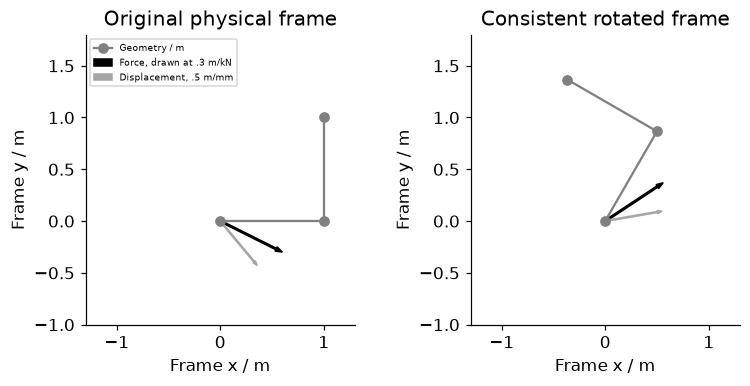

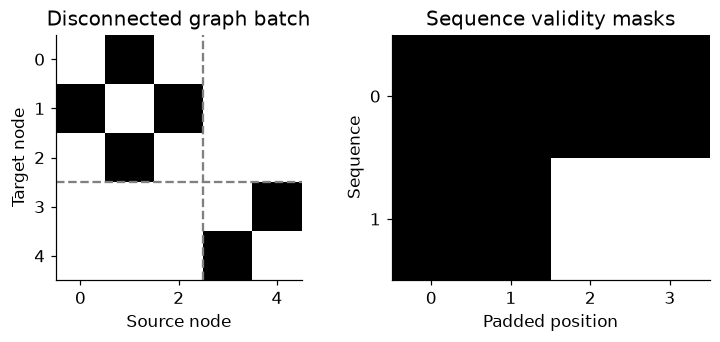

In [4]:
K=np.array([[4.,1.],[1.,2.]]);F=np.array([2.,-1.]);u=np.linalg.solve(K,F);angle=np.pi/3;R=np.array([[np.cos(angle),-np.sin(angle)],[np.sin(angle),np.cos(angle)]]);Knew=R@K@R.T;Fnew=R@F;unew=np.linalg.solve(Knew,Fnew);geometry=np.array([[0.,0.],[1.,0.],[1.,1.]])
np.testing.assert_allclose(unew,R@u);np.testing.assert_allclose(np.linalg.norm(unew),np.linalg.norm(u));np.testing.assert_allclose(unew@Fnew,u@F);assert not np.allclose(np.linalg.solve(K,Fnew),R@u)
rotated_geometry=geometry@R.T;np.testing.assert_allclose(np.linalg.norm(np.diff(rotated_geometry,axis=0),axis=1),np.linalg.norm(np.diff(geometry,axis=0),axis=1))
RESULTS['rotation']={'original_displacement_mm':u.tolist(),'rotated_displacement_mm':unew.tolist(),'magnitude_mm':float(np.linalg.norm(u)),'covariance_checks_passed':True,'unchanged_anisotropic_stiffness_detected_as_invalid':True}
fig,axes=plt.subplots(1,2,figsize=(7,3.4))
for ax,P,force,disp,title in zip(axes,[geometry,rotated_geometry],[F,Fnew],[u,unew],['Original physical frame','Consistent rotated frame']):
 ax.plot(P[:,0],P[:,1],marker='o',color='.5',label='Geometry / m');ax.arrow(0,0,force[0]*.3,force[1]*.3,width=.015,color='black',length_includes_head=True,label='Force, drawn at .3 m/kN');ax.arrow(0,0,disp[0]*.5,disp[1]*.5,width=.01,color='.65',length_includes_head=True,label='Displacement, .5 m/mm');ax.set(aspect='equal',xlim=(-1.3,1.3),ylim=(-1,1.8),xlabel='Frame x / m',ylabel='Frame y / m',title=title)
axes[0].legend(fontsize=6,loc='upper left');plt.show()
fig,axes=plt.subplots(1,2,figsize=(6.5,3));axes[0].imshow(A,cmap='Greys',vmin=0,vmax=1);axes[0].axhline(2.5,color='.5',ls='--');axes[0].axvline(2.5,color='.5',ls='--');axes[0].set(title='Disconnected graph batch',xlabel='Source node',ylabel='Target node');axes[1].imshow(mask,cmap='Greys',vmin=0,vmax=1,aspect='auto');axes[1].set(title='Sequence validity masks',xlabel='Padded position',ylabel='Sequence',yticks=[0,1],xticks=np.arange(4));plt.show()


In [5]:
summary={'example_id':'code_066','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['disconnected graph batching and offsets', 'mask-safe sequence aggregation', 'neighbor-sampling variability', 'covariant geometry loads stiffness and targets'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["disconnected graph batching and offsets", "mask-safe sequence aggregation", "neighbor-sampling variability", "covariant geometry loads stiffness and targets"], "elapsed_seconds": 0.15, "example_id": "code_066", "hardware": "Darwin arm64 CPU", "results": {"graph_batch": {"entities": 2, "no_cross_entity_edges": true, "nodes": 5, "pooled_means": [2.0, 15.0]}, "masked_sequence_means": [1.5, 5.0], "neighbor_sampling": {"all_uniform_pair_means": [0.0, 0.0, 50.0, 0.0, 50.0, 50.0], "full_mean": 25.0, "mean_over_pairs": 25.0}, "padding_perturbation_invariance": true, "rotation": {"covariance_checks_passed": true, "magnitude_mm": 1.1157499537009505, "original_displacement_mm": [0.7142857142857143, -0.8571428571428571], "rotated_displacement_mm": [1.0994503461009473, 0.19001814556031324], "unchanged_anisotropic_stiffness_detected_as_invalid": true}}, "seed": 1366, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python":